# OCTDL Image Quality Inspection

This notebook performs a read-only quality review of the OCTDL images using the cleaned manifest. It creates report-ready visualizations and analysis tables without modifying the raw images.

The inspection covers representative samples from every disease class, image dimensions, aspect ratios, readability, blank or near-blank appearance, and unusual records.

## 1. Imports and project paths

All analysis outputs are written below `data/processed/quality_inspection`. The raw OCTDL directory is read only.

In [1]:
from __future__ import annotations

import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, UnidentifiedImageError

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "font.size": 10,
})

def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "raw" / "OCTDL").is_dir():
            return candidate
    raise FileNotFoundError("Could not find a project root containing data/raw/OCTDL.")

PROJECT_ROOT = find_project_root()
MANIFEST_PATH = PROJECT_ROOT / "data" / "processed" / "manifest.csv"
OUTPUT_ROOT = PROJECT_ROOT / "data" / "processed" / "quality_inspection"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Manifest exists: {MANIFEST_PATH.is_file()}")
print(f"Output directory: {OUTPUT_ROOT}")

Project root: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin
Manifest exists: True
Output directory: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\data\processed\quality_inspection


## 2. Load the manifest and resolve image paths

The manifest stores project-relative paths. Only records marked `usable` are sampled for the visual grid, while all manifest rows are considered for the quality audit.

In [2]:
if not MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Manifest not found: {MANIFEST_PATH}")

manifest = pd.read_csv(MANIFEST_PATH)
required_columns = {"image_path", "file_name", "patient_id", "disease", "usable"}
missing_columns = required_columns.difference(manifest.columns)
if missing_columns:
    raise ValueError(f"Manifest is missing columns: {sorted(missing_columns)}")

manifest["image_path_absolute"] = manifest["image_path"].map(lambda value: PROJECT_ROOT / str(value))
manifest["image_exists"] = manifest["image_path_absolute"].map(Path.is_file)
manifest["usable"] = manifest["usable"].astype(bool)
DISEASE_ORDER = ["AMD", "NO", "ERM", "DME", "RVO", "VID", "RAO"]

print(f"Manifest rows: {len(manifest):,}")
print(f"Existing image paths: {int(manifest['image_exists'].sum()):,}")
print("Disease counts:")
display(manifest["disease"].value_counts().reindex(DISEASE_ORDER))

Manifest rows: 2,064
Existing image paths: 2,064
Disease counts:


disease
AMD    1231
NO      332
ERM     155
DME     147
RVO     101
VID      76
RAO      22
Name: count, dtype: int64

## 3. Compute image quality metrics

For each image, the audit records readability, actual dimensions, aspect ratio, grayscale brightness statistics, dynamic range, and entropy. These measurements are diagnostic only and do not alter image pixels.

In [3]:
def image_quality_metrics(path: Path) -> dict[str, object]:
    result = {
        "readable": False,
        "actual_width": pd.NA,
        "actual_height": pd.NA,
        "aspect_ratio": pd.NA,
        "mean_intensity": pd.NA,
        "std_intensity": pd.NA,
        "min_intensity": pd.NA,
        "max_intensity": pd.NA,
        "dynamic_range": pd.NA,
        "entropy": pd.NA,
        "error": pd.NA,
    }
    if not path.is_file():
        result["error"] = "Missing file"
        return result
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            grayscale = image.convert("L")
            width, height = grayscale.size
            values = np.asarray(grayscale, dtype=np.float32)
            histogram = np.bincount(values.astype(np.uint8).ravel(), minlength=256)
            probabilities = histogram[histogram > 0] / values.size
            result.update({
                "readable": True,
                "actual_width": width,
                "actual_height": height,
                "aspect_ratio": width / height if height else pd.NA,
                "mean_intensity": float(values.mean()),
                "std_intensity": float(values.std()),
                "min_intensity": int(values.min()),
                "max_intensity": int(values.max()),
                "dynamic_range": int(values.max() - values.min()),
                "entropy": float(-(probabilities * np.log2(probabilities)).sum()),
            })
    except (OSError, UnidentifiedImageError, ValueError) as error:
        result["error"] = f"{type(error).__name__}: {error}"
    return result

metrics = pd.DataFrame(
    [image_quality_metrics(path) for path in manifest["image_path_absolute"]],
    index=manifest.index,
)
quality = pd.concat([manifest, metrics], axis=1)
quality["dimension_mismatch"] = (
    quality["readable"]
    & (pd.to_numeric(quality["image_width"], errors="coerce") != quality["actual_width"])
    | (pd.to_numeric(quality["image_height"], errors="coerce") != quality["actual_height"])
)

print(f"Readable images: {int(quality['readable'].sum()):,}")
print(f"Unreadable or missing images: {int((~quality['readable']).sum()):,}")
display(quality[["disease", "actual_width", "actual_height", "aspect_ratio", "mean_intensity", "std_intensity"]].head())

Readable images: 2,064
Unreadable or missing images: 0


,disease,actual_width,actual_height,aspect_ratio,mean_intensity,std_intensity
0,AMD,1101,410,2.685366,55.647167,41.348999
1,AMD,731,265,2.758491,51.488247,45.632118
2,AMD,1100,410,2.682927,69.584869,41.822750
3,AMD,882,321,2.747664,69.451187,46.537575
4,AMD,882,321,2.747664,61.816135,52.573933


## 4. Identify blank, near-blank, and unusual images

The thresholds below are intentionally conservative screening rules, not clinical labels. A flagged image should be reviewed visually before it is removed from a modeling dataset.

In [4]:
readable = quality["readable"]
quality["blank_or_near_blank"] = readable & (
    (quality["std_intensity"] < 5.0)
    | (quality["dynamic_range"] < 15)
    | (quality["entropy"] < 1.0)
)

readable_aspects = quality.loc[readable, "aspect_ratio"].astype(float)
aspect_low, aspect_high = readable_aspects.quantile([0.01, 0.99])
quality["unusual_aspect_ratio"] = readable & (
    (quality["aspect_ratio"] < aspect_low)
    | (quality["aspect_ratio"] > aspect_high)
)
quality["unusual_dimensions"] = readable & (
    (quality["actual_width"] < 256)
    | (quality["actual_height"] < 128)
    | quality["dimension_mismatch"]
)
quality["potentially_unusual"] = (
    ~quality["readable"]
    | quality["blank_or_near_blank"]
    | quality["unusual_aspect_ratio"]
    | quality["unusual_dimensions"]
)

flag_columns = ["image_path", "file_name", "patient_id", "disease", "readable", "error", "actual_width", "actual_height", "aspect_ratio", "mean_intensity", "std_intensity", "dynamic_range", "entropy", "blank_or_near_blank", "unusual_aspect_ratio", "unusual_dimensions", "potentially_unusual"]
flagged = quality.loc[quality["potentially_unusual"], flag_columns].copy()
flagged.to_csv(OUTPUT_ROOT / "flagged_images.csv", index=False)
quality_metrics = quality.drop(columns=["image_path_absolute"])
quality_metrics.to_csv(OUTPUT_ROOT / "image_quality_metrics.csv", index=False)

print(f"Aspect-ratio screening range: {aspect_low:.3f} to {aspect_high:.3f}")
print(f"Blank or near-blank images: {int(quality['blank_or_near_blank'].sum()):,}")
print(f"Unusual aspect-ratio images: {int(quality['unusual_aspect_ratio'].sum()):,}")
print(f"Unusual-dimension images: {int(quality['unusual_dimensions'].sum()):,}")
print(f"Potentially unusual images: {len(flagged):,}")

Aspect-ratio screening range: 2.353 to 3.170
Blank or near-blank images: 0
Unusual aspect-ratio images: 41
Unusual-dimension images: 1
Potentially unusual images: 41


## 5. Report-ready random image grids

The grid uses a fixed random seed and samples up to eight usable images per disease class. The same seed makes the figure reproducible for project documentation.

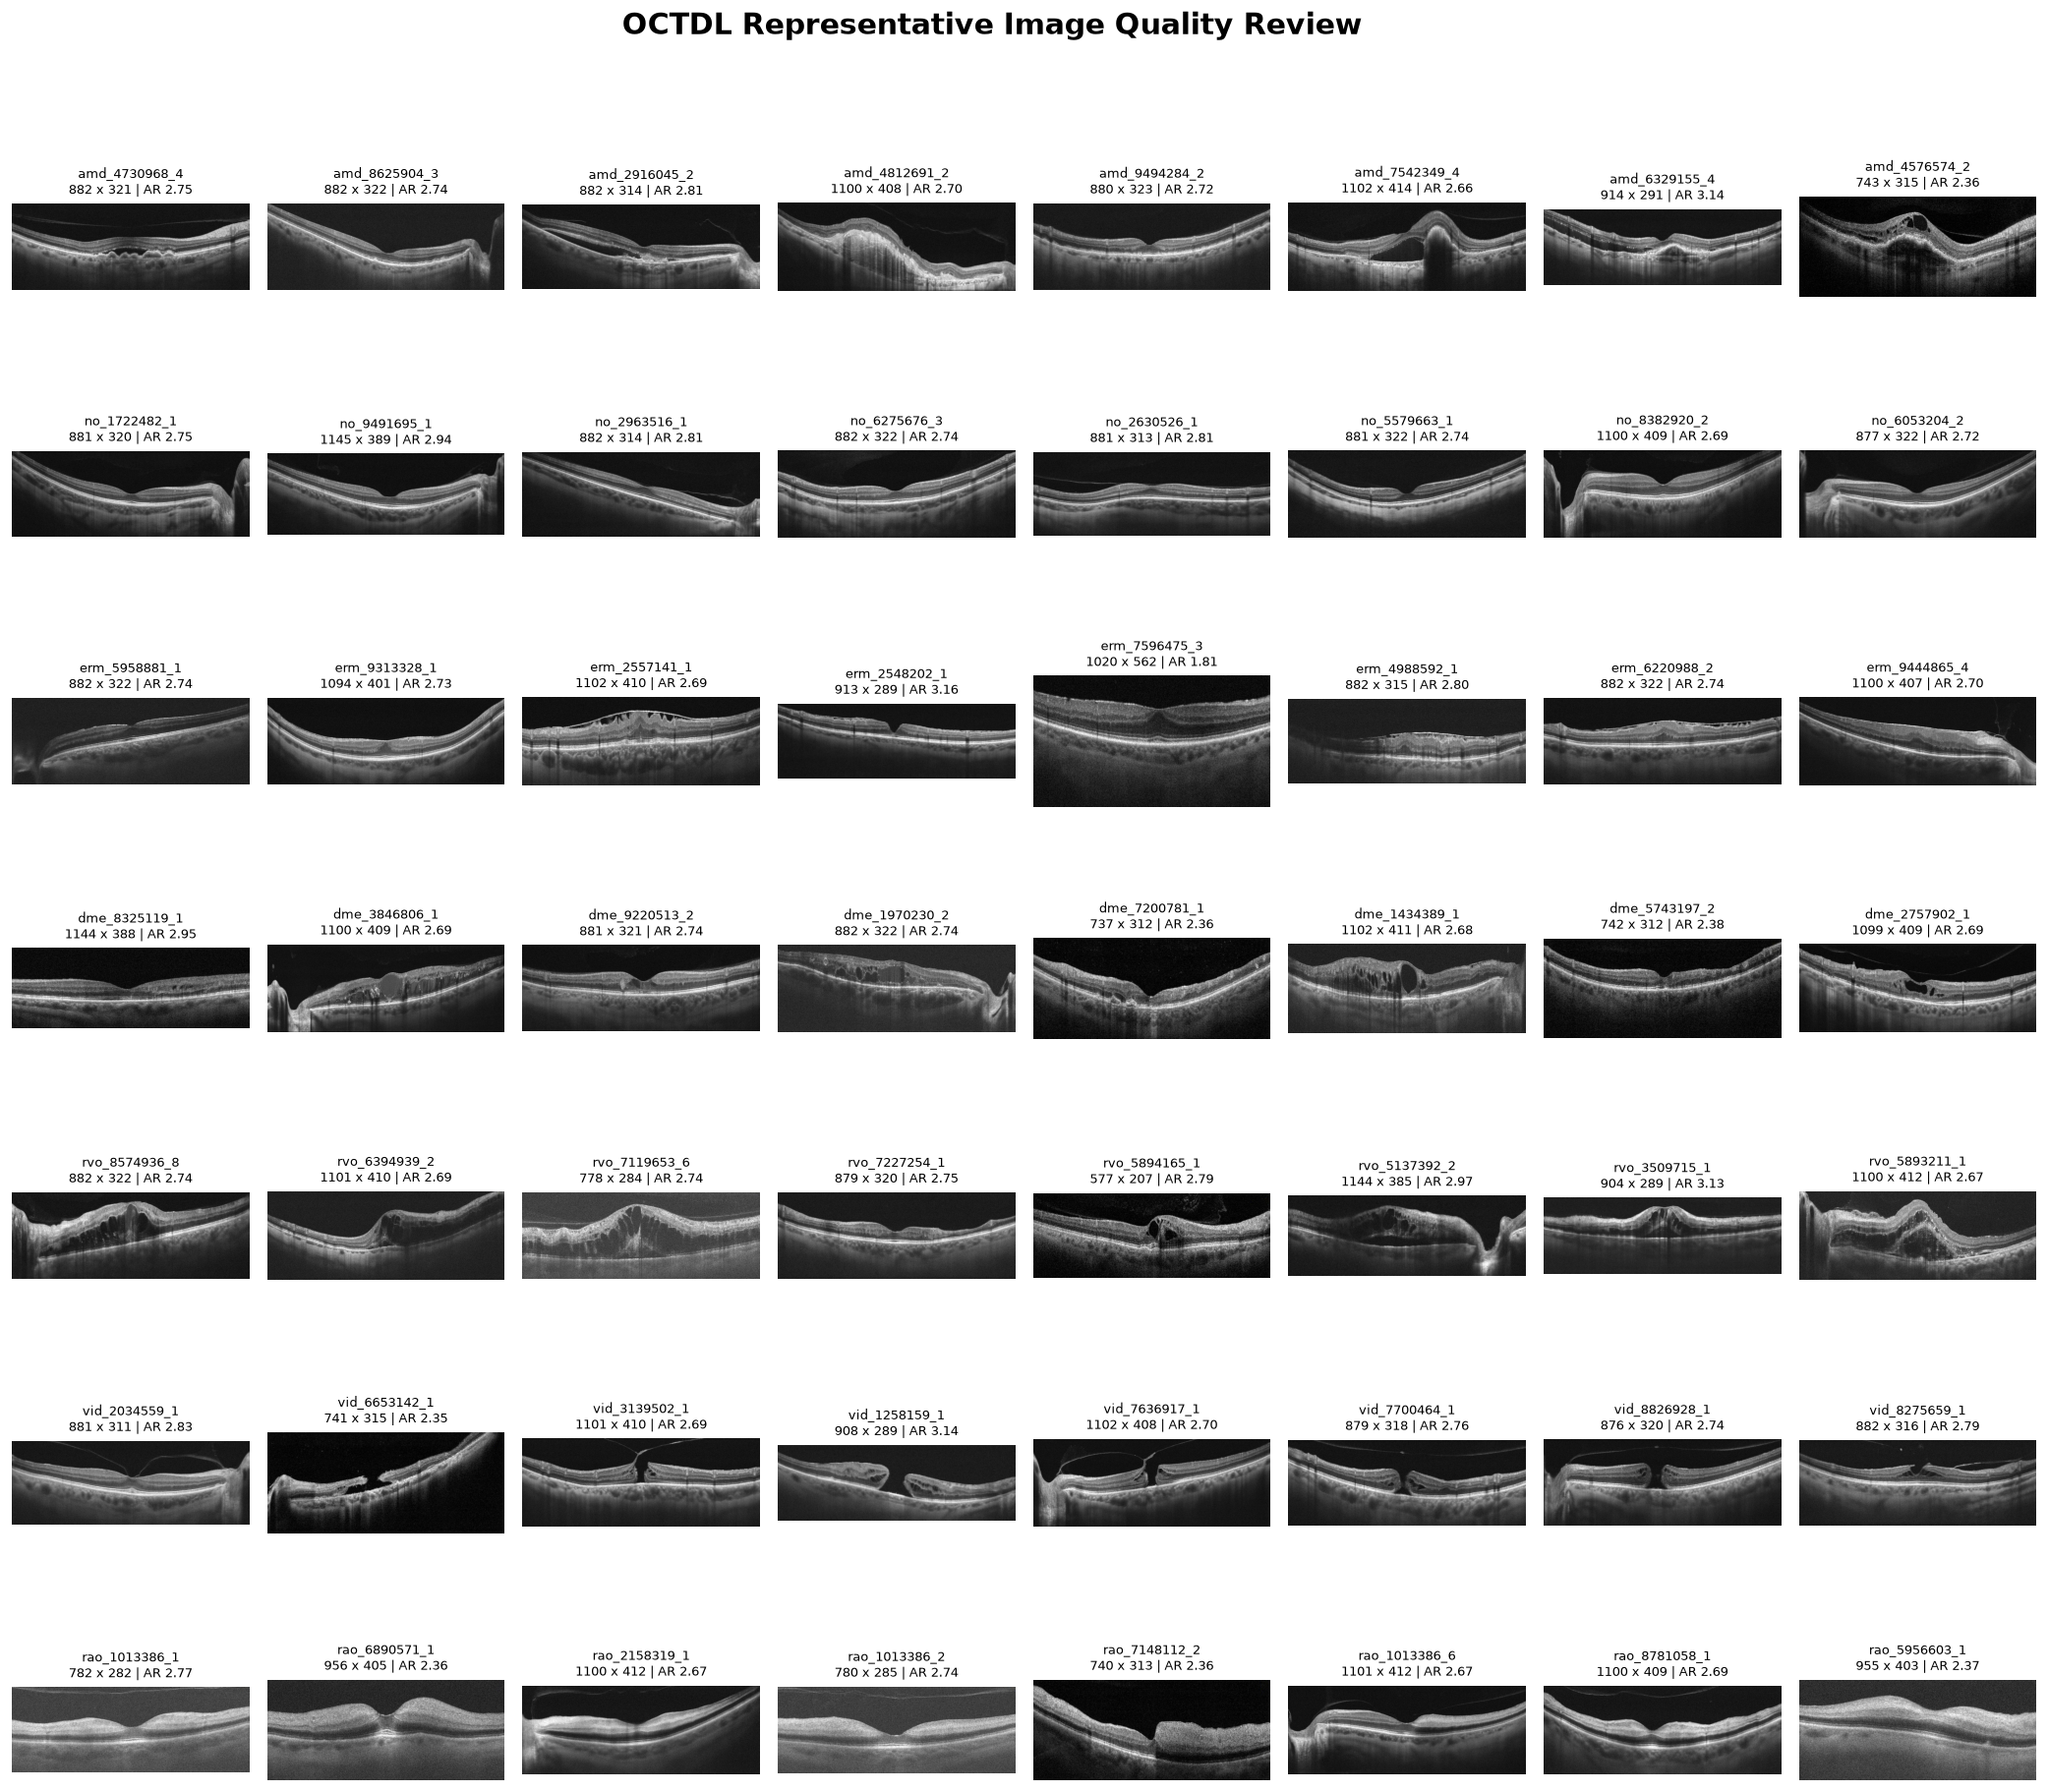

Saved: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\data\processed\quality_inspection\figures\octdl_representative_quality_grid.png


In [5]:
RANDOM_SEED = 42
SAMPLES_PER_CLASS = 8
rng = np.random.default_rng(RANDOM_SEED)
sampled_parts = []
for disease in DISEASE_ORDER:
    disease_rows = quality[(quality["disease"] == disease) & quality["readable"]].copy()
    sample_size = min(SAMPLES_PER_CLASS, len(disease_rows))
    if sample_size:
        sampled_parts.append(disease_rows.sample(n=sample_size, random_state=RANDOM_SEED))
sampled = pd.concat(sampled_parts, ignore_index=True)
sampled.to_csv(OUTPUT_ROOT / "sampled_images.csv", index=False)

columns = SAMPLES_PER_CLASS
rows = len(DISEASE_ORDER)
fig, axes = plt.subplots(rows, columns, figsize=(18, 16), squeeze=False)
fig.suptitle("OCTDL Representative Image Quality Review", fontsize=18, fontweight="bold", y=0.995)
for row_index, disease in enumerate(DISEASE_ORDER):
    disease_sample = sampled[sampled["disease"] == disease].reset_index(drop=True)
    for column_index in range(columns):
        axis = axes[row_index, column_index]
        axis.axis("off")
        if column_index >= len(disease_sample):
            continue
        record = disease_sample.iloc[column_index]
        with Image.open(record["image_path_absolute"]) as image:
            axis.imshow(image, cmap="gray")
        axis.set_title(f"{record['file_name']}\n{record['actual_width']} x {record['actual_height']} | AR {record['aspect_ratio']:.2f}", fontsize=8)
    axes[row_index, 0].set_ylabel(disease, rotation=0, labelpad=35, fontsize=11, fontweight="bold", va="center")
fig.tight_layout(rect=[0.03, 0, 1, 0.98])
grid_path = FIGURE_ROOT / "octdl_representative_quality_grid.png"
fig.savefig(grid_path, bbox_inches="tight")
plt.show()
print(f"Saved: {grid_path}")

## 6. Dimension and quality summary figures

These figures are suitable for inclusion in the data-preparation section of a project report.

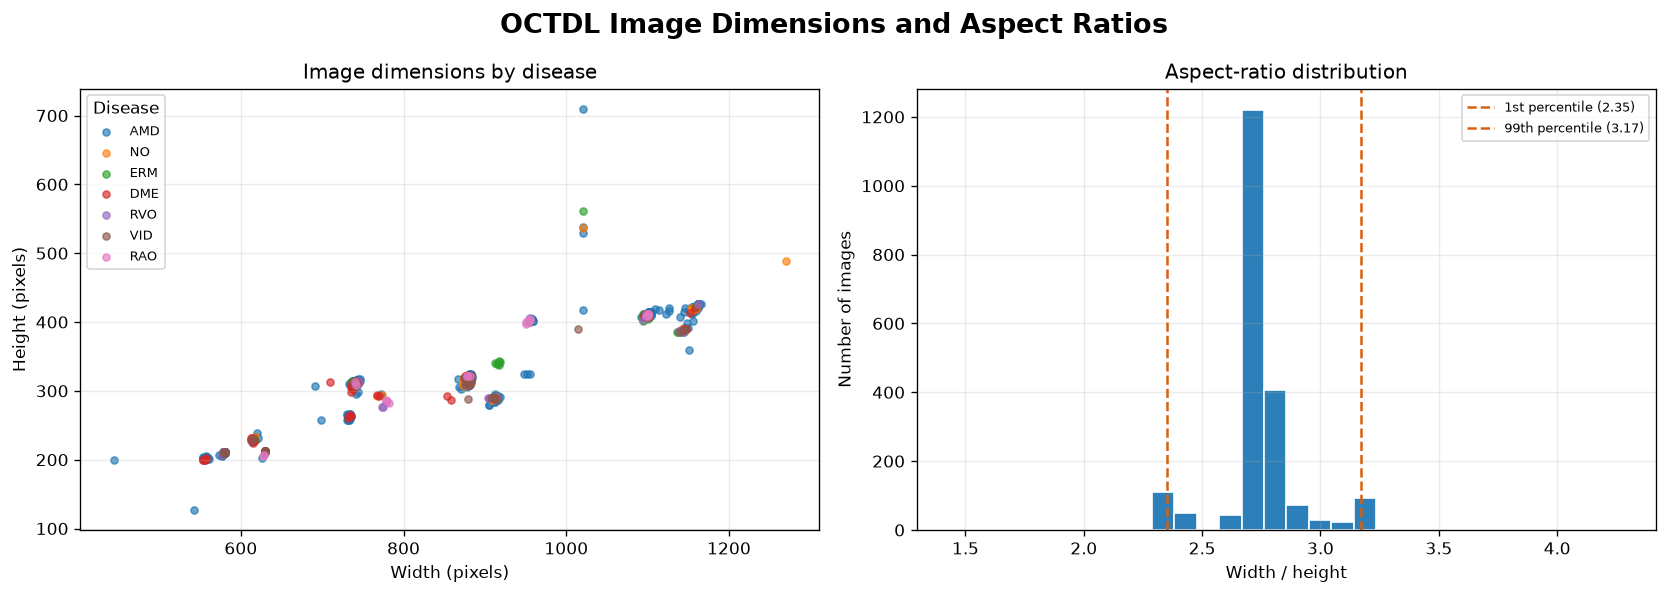

Saved: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\data\processed\quality_inspection\figures\octdl_dimensions_and_aspect_ratios.png


In [6]:
readable_quality = quality[quality["readable"]].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("OCTDL Image Dimensions and Aspect Ratios", fontsize=16, fontweight="bold")
for disease in DISEASE_ORDER:
    subset = readable_quality[readable_quality["disease"] == disease]
    axes[0].scatter(subset["actual_width"], subset["actual_height"], s=18, alpha=0.65, label=disease)
axes[0].set_title("Image dimensions by disease")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Height (pixels)")
axes[0].legend(title="Disease", fontsize=8)
axes[0].grid(alpha=0.25)
axes[1].hist(readable_quality["aspect_ratio"], bins=30, color="#2c7fb8", edgecolor="white")
axes[1].axvline(aspect_low, color="#d95f0e", linestyle="--", label=f"1st percentile ({aspect_low:.2f})")
axes[1].axvline(aspect_high, color="#d95f0e", linestyle="--", label=f"99th percentile ({aspect_high:.2f})")
axes[1].set_title("Aspect-ratio distribution")
axes[1].set_xlabel("Width / height")
axes[1].set_ylabel("Number of images")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.25)
fig.tight_layout()
dimension_path = FIGURE_ROOT / "octdl_dimensions_and_aspect_ratios.png"
fig.savefig(dimension_path, bbox_inches="tight")
plt.show()
print(f"Saved: {dimension_path}")

## 7. Final inspection report

Review `flagged_images.csv` and the saved figures before deciding whether any record should be excluded from model training. A screening flag is not by itself evidence of a bad image.

In [7]:
inspection_report = {
    "Total images": len(quality),
    "Readable images": int(quality["readable"].sum()),
    "Unreadable or missing images": int((~quality["readable"]).sum()),
    "Blank or near-blank images": int(quality["blank_or_near_blank"].sum()),
    "Unusual aspect-ratio images": int(quality["unusual_aspect_ratio"].sum()),
    "Unusual-dimension images": int(quality["unusual_dimensions"].sum()),
    "Potentially unusual images": int(quality["potentially_unusual"].sum()),
}

report_table = pd.DataFrame([inspection_report])
report_table.to_csv(OUTPUT_ROOT / "inspection_report.csv", index=False)
print("Final image quality inspection report")
print("-" * 38)
for metric, value in inspection_report.items():
    print(f"{metric}: {value:,}")
print(f"\nSaved analysis results to: {OUTPUT_ROOT}")
print(f"Saved figures to: {FIGURE_ROOT}")

Final image quality inspection report
--------------------------------------
Total images: 2,064
Readable images: 2,064
Unreadable or missing images: 0
Blank or near-blank images: 0
Unusual aspect-ratio images: 41
Unusual-dimension images: 1
Potentially unusual images: 41

Saved analysis results to: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\data\processed\quality_inspection
Saved figures to: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\data\processed\quality_inspection\figures
